# 01 – Explorácia dát (FraudSquad / Amazon)

Explorácia datasetu pred čistením, trénovaním etc.

- vstup: `amazon_real.csv` (pravé recenzie, label 0) a tri súbory so spamom z LLM generátorov (label 1)
- konfigurácia ciest a názvov stĺpcov v druhej bunke

In [40]:
from pathlib import Path

DATA = Path("../../data/FraudSquad-Data/Amazon")

REAL_PATH = DATA / "amazon_real.csv"           # pravé recenzie, ~86k riadkov, bez stĺpca label
SPAM_PATHS = {
    "llama3":    DATA / "reviews_from_llama3_8b.csv",
    "qwen_72b":     DATA / "reviews_from_qwen_72b.csv",
    "qwen_dsr1": DATA / "reviews_from_qwen_dsr1.csv",
}

COL = {
    "text":    "reviewText",
    "rating":  "star",
    "product": "product",
    "user":    "user",
    "time":    "reviewTime",
}

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def load(path):
    path = Path(path)
    ext = path.suffix.lower()
    if ext == ".csv":
        return pd.read_csv(path)
    if ext == ".jsonl":
        return pd.read_json(path, lines=True)
    if ext == ".json":
        try:
            return pd.read_json(path)
        except ValueError:
            return pd.read_json(path, lines=True)
    if ext == ".parquet":
        return pd.read_parquet(path)
    raise ValueError(f"Neznámy formát súboru: {ext}")

real = load(REAL_PATH)
spam = {name: load(p) for name, p in SPAM_PATHS.items()}

## 1. Rozmery a stĺpce
Rozmery datasetov, zoznam stĺpcov, riadky.

In [42]:
print("real:", real.shape)
print(real.columns.tolist())
display(real.head(3))
for name, d in spam.items():
    print()
    print(name, d.shape)
    print(d.columns.tolist())
    display(d.head(2))

real: (86758, 17)
['star', 'reviewSummary', 'reviewText', 'images', 'product_child', 'product', 'user', 'reviewTime', 'helpful_vote', 'verified_purchase', 'product_category', 'reviewDay', 'reviewMonth', 'reviewYear', 'product_star', 'product_month', 'product_day']


,star,reviewSummary,reviewText,images,product_child,product,user,reviewTime,helpful_vote,verified_purchase,product_category,reviewDay,reviewMonth,reviewYear,product_star,product_month,product_day
0,4.0,reef rescue,I like this game ok... but wish there were les...,[],B0788DHDKG,B0788DHDKG,AFZUK3MTBIBEDQOPAK3OATUOUKLA,1644728773,11,True,Software,2022-02-13,2022-02,2022,B0788DHDKG_4.0,B0788DHDKG_2022-02,B0788DHDKG_2022-02-13
1,5.0,Good Product,Good Product,[],B00E81O27Y,B00E81O27Y,AFDMZ4TRX3HXQQUGWAHJQTIF65BQ,1643755169,0,True,Software,2022-02-02,2022-02,2022,B00E81O27Y_5.0,B00E81O27Y_2022-02,B00E81O27Y_2022-02-02
2,5.0,Good Product,Good Product,[],B07T771SPH,B07T771SPH,AFDMZ4TRX3HXQQUGWAHJQTIF65BQ,1643580358,0,True,Software,2022-01-31,2022-01,2022,B07T771SPH_5.0,B07T771SPH_2022-01,B07T771SPH_2022-01-31



llama3 (2489, 18)
['star', 'reviewSummary', 'reviewText', 'images', 'product_child', 'product', 'user', 'reviewTime', 'helpful_vote', 'verified_purchase', 'product_category', 'reviewDay', 'reviewMonth', 'reviewYear', 'product_star', 'product_month', 'product_day', 'label']


,star,reviewSummary,reviewText,images,product_child,product,user,reviewTime,helpful_vote,verified_purchase,product_category,reviewDay,reviewMonth,reviewYear,product_star,product_month,product_day,label
0,5.0,NaN,I was blown away by the longevity of this frag...,[],B00BH4N3OI,B00BH4N3OI,AHDDJHDUD6ESXMMXINH6PF4RFRRA,1651503614,0,False,All_Beauty,2022-05-02,2022-05,2022,B00BH4N3OI_1.0,B00BH4N3OI_2022-05,B00BH4N3OI_2022-05-02,1
1,5.0,NaN,Gucci really knows how to deliver when it come...,[],B00BH4N3OI,B00BH4N3OI,AH3NR6XSWEZ6KZEWH52WYA5CBZMQ,1651615214,0,False,All_Beauty,2022-05-02,2022-05,2022,B00BH4N3OI_1.0,B00BH4N3OI_2022-05,B00BH4N3OI_2022-05-02,1



qwen_72b (2495, 18)
['star', 'reviewSummary', 'reviewText', 'images', 'product_child', 'product', 'user', 'reviewTime', 'helpful_vote', 'verified_purchase', 'product_category', 'reviewDay', 'reviewMonth', 'reviewYear', 'product_star', 'product_month', 'product_day', 'label']


,star,reviewSummary,reviewText,images,product_child,product,user,reviewTime,helpful_vote,verified_purchase,product_category,reviewDay,reviewMonth,reviewYear,product_star,product_month,product_day,label
0,5.0,NaN,Gucci Pour Homme Eau De Toilette Spray is an e...,[],B00BH4N3OI,B00BH4N3OI,AGFSTOK4EATV3KIYE4P6UPN5ZG7A,1651730414,0,False,All_Beauty,2022-05-02,2022-05,2022,B00BH4N3OI_1.0,B00BH4N3OI_2022-05,B00BH4N3OI_2022-05-02,1
1,5.0,NaN,I was a bit skeptical about online perfume pur...,[],B00BH4N3OI,B00BH4N3OI,AHPG65LKS3QKRWDUWAKZNLEK5RZQ_1,1651842014,0,False,All_Beauty,2022-05-02,2022-05,2022,B00BH4N3OI_1.0,B00BH4N3OI_2022-05,B00BH4N3OI_2022-05-02,1



qwen_dsr1 (2500, 18)
['star', 'reviewSummary', 'reviewText', 'images', 'product_child', 'product', 'user', 'reviewTime', 'helpful_vote', 'verified_purchase', 'product_category', 'reviewDay', 'reviewMonth', 'reviewYear', 'product_star', 'product_month', 'product_day', 'label']


,star,reviewSummary,reviewText,images,product_child,product,user,reviewTime,helpful_vote,verified_purchase,product_category,reviewDay,reviewMonth,reviewYear,product_star,product_month,product_day,label
0,5.0,NaN,I absolutely love this Gucci perfume! The scen...,[],B00BH4N3OI,B00BH4N3OI,AHWHTYPZETP3Z7KHK4QT4QH4QZBQ,1651489214,0,False,All_Beauty,2022-05-02,2022-05,2022,B00BH4N3OI_1.0,B00BH4N3OI_2022-05,B00BH4N3OI_2022-05-02,1
1,5.0,NaN,This perfume exceeded my expectations! The ble...,[],B00BH4N3OI,B00BH4N3OI,AFATMDPOJFTSH3RHPLGNS7QF43ZA,1651528814,0,False,All_Beauty,2022-05-02,2022-05,2022,B00BH4N3OI_1.0,B00BH4N3OI_2022-05,B00BH4N3OI_2022-05-02,1


## 2. Zloženie datasetu
- pravé recenzie sú spoločné pre všetky tri generátory
- samostatný dataset pre každý generátor: pravé (label 0) + spam z daného generátora (label 1)
- output: počet riadkov, podiel spamu

In [43]:
def make(name):
    return pd.concat(
        [real.assign(label=0, source="human"),
         spam[name].assign(label=1, source=name)],
        ignore_index=True,
    )

for name in spam:
    d = make(name)
    print(f"{name:10s} riadkov: {len(d):>7}  podiel spamu: {d['label'].mean():.4f}")

llama3     riadkov:   89247  podiel spamu: 0.0279
qwen_72b   riadkov:   89253  podiel spamu: 0.0280
qwen_dsr1  riadkov:   89258  podiel spamu: 0.0280


## 3. Distribúcia hodnotenia (`star`)

In [44]:
r = COL["rating"]
if r in real.columns and all(r in d.columns for d in spam.values()):
    print("real:")
    print(real[r].value_counts(normalize=True).sort_index().round(3).to_dict())
    for name, d in spam.items():
        print(name, d[r].value_counts(normalize=True).sort_index().round(3).to_dict())
else:
    print("Stĺpec s hodnotením chýba, krok preskočený.")

real:
{1.0: 0.037, 2.0: 0.023, 3.0: 0.068, 4.0: 0.175, 5.0: 0.696}
llama3 {5.0: 1.0}
qwen_72b {5.0: 1.0}
qwen_dsr1 {5.0: 1.0}


## 4. Dĺžka textu
- počet slov v `reviewText`
- referencia: pravé 5★ recenzie (spam má vždy 5★)
- histogram orezaný na 200 slov
- počet prázdnych textov
- ROC-AUC klasifikácie len z počtu slov

       real (5★)  llama3  qwen_72b  qwen_dsr1
count    60360.0  2489.0    2495.0     2500.0
mean        64.4    56.5      54.5       59.1
std         78.6     7.4       8.7       10.1
min          0.0    10.0      31.0       31.0
25%         18.0    52.0      49.0       52.0
50%         43.0    56.0      53.0       59.0
75%         81.0    61.0      60.0       66.0
max       2366.0    94.0     133.0      102.0


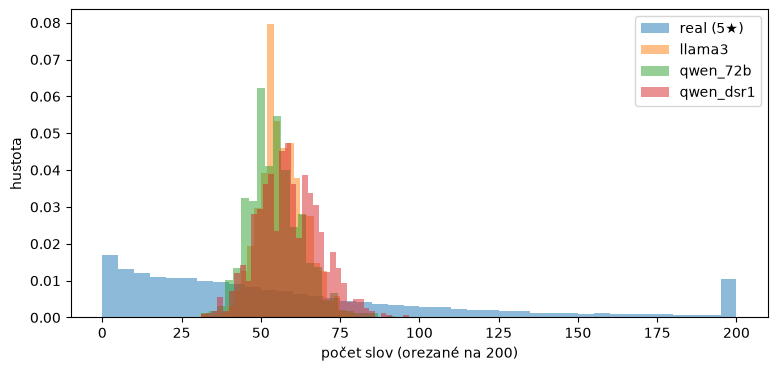

In [45]:
txt, r = COL["text"], COL["rating"]

def words(s):
    return s.fillna("").astype(str).str.split().str.len()

if r in real.columns:
    real_ref = real[real[r] >= 5]
    ref_label = "real (5★)"
else:
    real_ref = real
    ref_label = "real (všetky)"

lengths = {ref_label: words(real_ref[txt])}
for name, d in spam.items():
    lengths[name] = words(d[txt])

print(pd.DataFrame({k: v.describe() for k, v in lengths.items()}).round(1))

fig, ax = plt.subplots(figsize=(9, 4))
for k, v in lengths.items():
    ax.hist(v.clip(upper=200), bins=40, alpha=0.5, density=True, label=k)
ax.set_xlabel("počet slov (orezané na 200)")
ax.set_ylabel("hustota")
ax.legend()
plt.show()

In [46]:
for name, d in [("real", real)] + list(spam.items()):
    print(f"{name:10s} prázdny text: {d[COL['text']].isna().sum()}")

real       prázdny text: 61
llama3     prázdny text: 0
qwen_72b   prázdny text: 0
qwen_dsr1  prázdny text: 0


In [47]:
# ROC-AUC len z počtu slov: spam vs. pravé 5★
from sklearn.metrics import roc_auc_score

for name in spam:
    y = np.r_[np.zeros(len(lengths[ref_label])), np.ones(len(lengths[name]))]
    x = np.r_[lengths[ref_label].values, lengths[name].values]
    print(f"{name:10s} AUC len-only: {roc_auc_score(y, x):.3f}")

llama3     AUC len-only: 0.608
qwen_72b   AUC len-only: 0.592
qwen_dsr1  AUC len-only: 0.623


## 5. Duplicity a prekryv textov
- duplicitné texty v pravých recenziách a v spame
- spam texty, ktoré sa nachádzajú aj medzi pravými recenziami
- duplicity medzi train a test skresľujú evaluáciu

In [48]:
pool = set(real[txt])
print("duplicit v real:", real[txt].duplicated().sum())
for name, d in spam.items():
    print(f"{name:10s} duplicit v spame: {d[txt].duplicated().sum():>5}"
          f"  | spam texty, ktoré sú aj v real: {d[txt].isin(pool).sum()}")

duplicit v real: 7230
llama3     duplicit v spame:     0  | spam texty, ktoré sú aj v real: 0
qwen_72b   duplicit v spame:     0  | spam texty, ktoré sú aj v real: 0
qwen_dsr1  duplicit v spame:     0  | spam texty, ktoré sú aj v real: 0


## 6. Chýbajúce hodnoty
Počet `NaN` v každom stĺpci.

In [49]:
print("real:")
print(real.isna().sum().to_dict())
for name, d in spam.items():
    print(name, d.isna().sum().to_dict())

real:
{'star': 0, 'reviewSummary': 27, 'reviewText': 61, 'images': 0, 'product_child': 0, 'product': 0, 'user': 0, 'reviewTime': 0, 'helpful_vote': 0, 'verified_purchase': 0, 'product_category': 0, 'reviewDay': 0, 'reviewMonth': 0, 'reviewYear': 0, 'product_star': 0, 'product_month': 0, 'product_day': 0}
llama3 {'star': 0, 'reviewSummary': 2489, 'reviewText': 0, 'images': 0, 'product_child': 0, 'product': 0, 'user': 0, 'reviewTime': 0, 'helpful_vote': 0, 'verified_purchase': 0, 'product_category': 0, 'reviewDay': 0, 'reviewMonth': 0, 'reviewYear': 0, 'product_star': 0, 'product_month': 0, 'product_day': 0, 'label': 0}
qwen_72b {'star': 0, 'reviewSummary': 2495, 'reviewText': 0, 'images': 0, 'product_child': 0, 'product': 0, 'user': 0, 'reviewTime': 0, 'helpful_vote': 0, 'verified_purchase': 0, 'product_category': 0, 'reviewDay': 0, 'reviewMonth': 0, 'reviewYear': 0, 'product_star': 0, 'product_month': 0, 'product_day': 0, 'label': 0}
qwen_dsr1 {'star': 0, 'reviewSummary': 2500, 'review

## 7. Produkty a používatelia
- počet produktov, počet spam recenzií na produkt
- prekryv produktov a používateľov medzi spamom a pravými recenziami
- podklad pre rozdelenie podľa produktu (pravé recenzie aj spam jedného produktu v tej istej časti)

In [50]:
p, u = COL["product"], COL["user"]
if p in real.columns:
    print("produktov v real:", real[p].nunique())
    for name, d in spam.items():
        per = d.groupby(p).size()
        print(f"{name:10s} produktov: {d[p].nunique():>4}  spam na produkt (min/medián/max): "
              f"{per.min()}/{int(per.median())}/{per.max()}  "
              f"podiel produktov aj v real: {d[p].isin(set(real[p])).mean():.3f}")
else:
    print("Stĺpec s produktom chýba.")

if u in real.columns:
    for name, d in spam.items():
        print(f"{name:10s} podiel spam používateľov, ktorí sú aj v real: {d[u].isin(set(real[u])).mean():.3f}")

produktov v real: 7617
llama3     produktov:  499  spam na produkt (min/medián/max): 2/5/5  podiel produktov aj v real: 1.000
qwen_72b   produktov:  499  spam na produkt (min/medián/max): 5/5/5  podiel produktov aj v real: 1.000
qwen_dsr1  produktov:  500  spam na produkt (min/medián/max): 5/5/5  podiel produktov aj v real: 1.000
llama3     podiel spam používateľov, ktorí sú aj v real: 1.000
qwen_72b   podiel spam používateľov, ktorí sú aj v real: 1.000
qwen_dsr1  podiel spam používateľov, ktorí sú aj v real: 1.000


## Výsledok
- pravé recenzie: 86 758, 7 617 produktov; spam: 2 489 / 2 495 / 2 500 (llama3 / qwen_72b / qwen_dsr1); podiel spamu ~2,8 %
- hodnotenie: spam 100 % 5★, pravé 69,6 % 5★
- dĺžka: spam priemer 54,5–59,1 slov, std 7,4–10,1; pravé 5★ priemer 64,4, std 78,6; ROC-AUC len z dĺžky 0,592–0,623
- duplicity: 7 230 v pravých, 0 v spame, 0 spoločných textov
- chýbajúce hodnoty: spam nemá `reviewSummary`; pravé majú 61 prázdnych `reviewText`
- spam: 499–500 produktov, typicky 5 recenzií na produkt; všetky produkty aj používatelia zo spamu sa vyskytujú aj v pravých dátach